Integrantes del grupo: Felipe Nahum, Felipe Boucai, Mauricio Boscolo.


In [1]:
import seaborn as sns
import seaborn.objects as so
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

from scipy import stats
import numpy as np
import pandas as pd
from sklearn import linear_model 
from sklearn.metrics import mean_squared_error

from formulaic import Formula

In [2]:
datos_sube = pd.read_csv('./data/sube-2023.csv')

# Procesamiento de datos

## Ejercicio 1
### a)

In [3]:
datos_sube['DIA_TRANSPORTE'] = pd.to_datetime(datos_sube['DIA_TRANSPORTE'], format='%Y-%m-%d')
datos_sube.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472291 entries, 0 to 472290
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   DIA_TRANSPORTE   472291 non-null  datetime64[ns]
 1   NOMBRE_EMPRESA   472291 non-null  object        
 2   LINEA            472291 non-null  object        
 3   AMBA             472291 non-null  object        
 4   TIPO_TRANSPORTE  472291 non-null  object        
 5   JURISDICCION     469742 non-null  object        
 6   PROVINCIA        469720 non-null  object        
 7   MUNICIPIO        469720 non-null  object        
 8   CANTIDAD         472291 non-null  int64         
 9   DATO_PRELIMINAR  472291 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(8)
memory usage: 36.0+ MB


### b)
#### i)

In [4]:
datos_sube['FECHA_DIA'] = datos_sube['DIA_TRANSPORTE'].dt.dayofweek
datos_sube = datos_sube.replace({'FECHA_DIA': {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}})

#### ii)

In [5]:
datos_sube['FECHA_ORDINAL'] = datos_sube['DIA_TRANSPORTE'].apply(lambda x: x.toordinal() - 738520)
##738520 es la cantidad de dias que pasaron desde el 01-01-01 hasta el 2023-01-01, debe haber otra forma de hacerlo igual.

#### iii)

In [6]:
datos_sube['FECHA_MES'] = datos_sube['DIA_TRANSPORTE'].dt.month

## Ejercicio 2

In [7]:
amba = datos_sube[datos_sube.AMBA == 'SI']
datos_amba = pd.DataFrame()
datos_amba['fecha'] = amba['DIA_TRANSPORTE']
datos_amba['fecha_dia'] = amba['FECHA_DIA']
datos_amba['fecha_mes'] = amba['FECHA_MES']
datos_amba['fecha_ordinal'] = amba['FECHA_ORDINAL']
datos_amba['jurisdiccion'] = amba['JURISDICCION']
datos_amba['linea'] = amba['LINEA']
datos_amba['pasajeros'] = amba['CANTIDAD']
datos_amba['tipo_transporte'] = amba['TIPO_TRANSPORTE']

In [8]:
datos_amba.head()

,fecha,fecha_dia,fecha_mes,fecha_ordinal,jurisdiccion,linea,pasajeros,tipo_transporte
0,2023-01-01,Sun,1,1,MUNICIPAL,1,61,COLECTIVO
1,2023-01-01,Sun,1,1,MUNICIPAL,2B,11,COLECTIVO
3,2023-01-01,Sun,1,1,PROVINCIAL,BS_AS_LINEA_326,438,COLECTIVO
5,2023-01-01,Sun,1,1,MUNICIPAL,BS_AS_LINEA_514,3067,COLECTIVO
6,2023-01-01,Sun,1,1,MUNICIPAL,BS_AS_LINEA_522,332,COLECTIVO


## Ejercicio 3
### a)

In [9]:
cantidad_por_tipo = datos_amba.groupby('tipo_transporte')['pasajeros'].sum()
pasajeros_total = cantidad_por_tipo.sum()

In [10]:
proporcion = cantidad_por_tipo / pasajeros_total
proporcion

tipo_transporte
COLECTIVO    0.837677
SUBTE        0.068084
TREN         0.094240
Name: pasajeros, dtype: float64

##### Grafico de los datos obtenidos

([<matplotlib.patches.Wedge at 0x147a5dae0>,
 [Text(-0.9600442361560029, 0.5369497784929584, 'COLECTIVO'),
  Text(0.7616171139225699, -0.7936872002119321, 'SUBTE'),
  Text(1.0521420938653665, -0.32093147916121084, 'TREN')],
 [Text(-0.5236604924487288, 0.29288169735979547, '84%'),
  Text(0.4154275166850381, -0.43292029102469015, '7%'),
  Text(0.5738956875629271, -0.17505353408793317, '9%')])

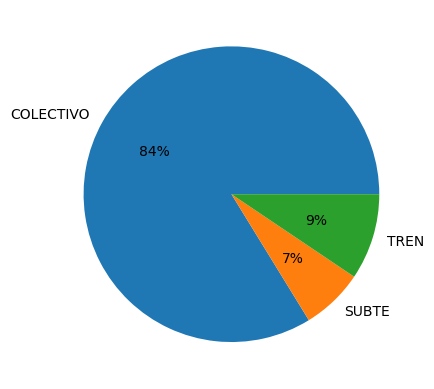

In [11]:
plt.pie(cantidad_por_tipo, labels=proporcion.index, autopct= '%0.0f%%')

### b)

In [12]:
datos_subte = datos_amba[datos_amba['tipo_transporte'] == 'SUBTE']
suma_por_mes = datos_subte.groupby(['fecha_mes', 'linea'])['pasajeros'].sum()
suma_por_mes

fecha_mes  linea        
1          LINEA SUBTE C    2650875
           LINEA SUBTE D    3357804
           LINEA SUBTE E    1288478
           LINEA SUBTE H    1591342
           LINEA_A          3186254
                             ...   
12         LINEA SUBTE E    1637759
           LINEA SUBTE H    1950958
           LINEA_A          4374190
           LINEA_B          4802180
           LIN_PREMETRO       37417
Name: pasajeros, Length: 84, dtype: int64

In [13]:
mas_pasajeros = suma_por_mes.idxmax()
mas_pasajeros

(8, 'LINEA_B')

### c)

In [14]:
dias_habiles = datos_amba[datos_amba['fecha_dia'].isin(['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])]
desviacion_std_por_dia = dias_habiles.groupby('fecha_dia')['pasajeros'].std()
desviacion_std_por_dia

fecha_dia
Fri    35056.183054
Mon    33573.895343
Thu    35964.585445
Tue    35830.872527
Wed    35977.215721
Name: pasajeros, dtype: float64

In [15]:
minima_desviacion = desviacion_std_por_dia.idxmin()
print(f'El dia habil con menor desviacion estandar es el {minima_desviacion}')

El dia habil con menor desviacion estandar es el Mon


*********************************************

# Análisis Exploratorio

##### Comparacion del uso de colectivos y trenes entre AMBA y no AMBA.  

In [16]:
#datos_sube = datos_sube[(datos_sube.FECHA_ORDINAL % 7)== 1]
#datos_sube = datos_sube.groupby(['FECHA_ORDINAL', 'TIPO_TRANSPORTE'])['CANTIDAD'].sum()
#datos_sube = pd.DataFrame(datos_sube)

datos_colectivo_tren = datos_sube[(datos_sube['TIPO_TRANSPORTE'] == 'COLECTIVO') | (datos_sube['TIPO_TRANSPORTE'] == 'TREN')][['FECHA_ORDINAL', 'CANTIDAD', 'TIPO_TRANSPORTE', 'AMBA']]
datos_colectivo_tren = datos_colectivo_tren.groupby(['FECHA_ORDINAL', 'TIPO_TRANSPORTE', 'AMBA'])['CANTIDAD'].sum().reset_index()

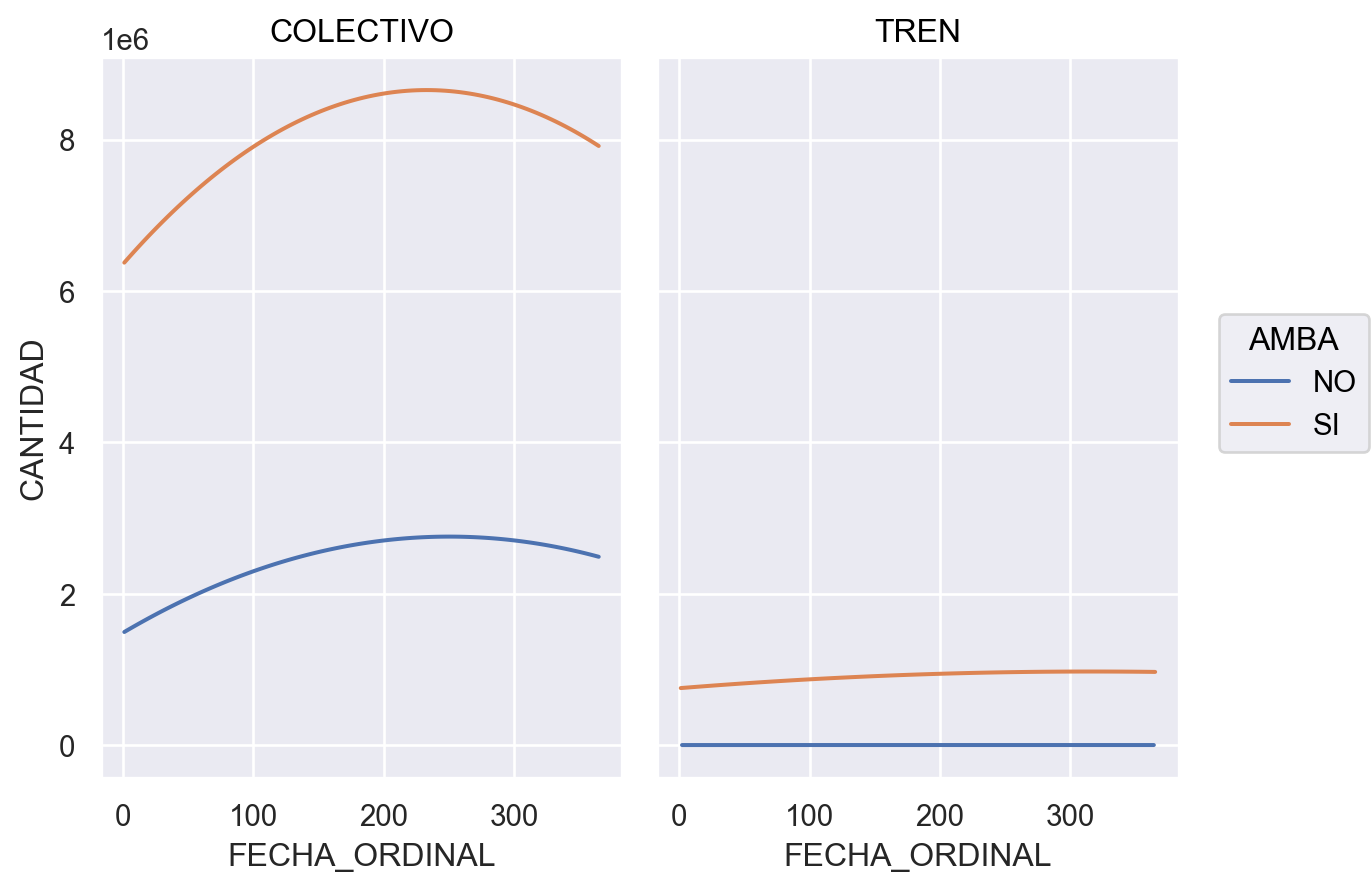

In [17]:
(
    so.Plot(
        data = datos_colectivo_tren,
        x = 'FECHA_ORDINAL',
        y = 'CANTIDAD',
        color = 'AMBA'
    )
    .add(so.Line(), so.PolyFit(2))
    .facet('TIPO_TRANSPORTE')
)

Al visualizar estos datos instantáneamente notamos la gran diferencia que hay entre el uso del tren y el colectivo, siendo este ultimo el mas utilizado a la hora de viajar. Otra diferencia muy importante que pudimos observar es que el margen de diferencia entre AMBA y no-AMBA es muy amplio en el grafico del colectivo, mientras que no es el caso para los trenes. Esto puede deberse a que en AMBA existen mas lineas de colectivo y es mas practico a la hora de moverse dentro de la ciudad

#### Grafico maximos/minimos por dia

In [18]:
#Cantidad de viajes registrados por dia (juntando todos los medio de transporte).
cantidad_por_dia_2023 = datos_sube.groupby('DIA_TRANSPORTE').CANTIDAD.sum()

In [19]:
#Calculo los extremos de 2023
sube_data_2023 = pd.read_csv('./data/sube-2023.csv') #Lo leo devuelta para que no tome a 'DIA_TRANSPORTE' como una fecha.

cantidad_por_dia_2023 = sube_data_2023.groupby('DIA_TRANSPORTE')['CANTIDAD'].sum().reset_index()

mayores_2023 = cantidad_por_dia_2023.nlargest(5, 'CANTIDAD')
menores_2023 = cantidad_por_dia_2023.nsmallest(5, 'CANTIDAD')

extremos_2023 = pd.concat([mayores_2023, menores_2023]).reset_index(drop= True)
extremos_2023['AÑO'] = 2023 

In [20]:
#Calculo los extremos de 2021
sube_data_2021 = pd.read_csv('./data/dat-ab-usos-2021.csv') #Lo leo devuelta para que no tome a 'DIA_TRANSPORTE' como una fecha.

cantidad_por_dia_2021 = sube_data_2021.groupby('DIA_TRANSPORTE')['CANTIDAD'].sum().reset_index()

mayores_2021 = cantidad_por_dia_2021.nlargest(5, 'CANTIDAD')
menores_2021 = cantidad_por_dia_2021.nsmallest(5, 'CANTIDAD')

extremos_2021 = pd.concat([mayores_2021, menores_2021]).reset_index(drop= True)
extremos_2021['AÑO'] = 2021

extremos = pd.concat([extremos_2023, extremos_2021]).reset_index(drop= True)
extremos_ord = extremos.sort_values(by = 'DIA_TRANSPORTE')

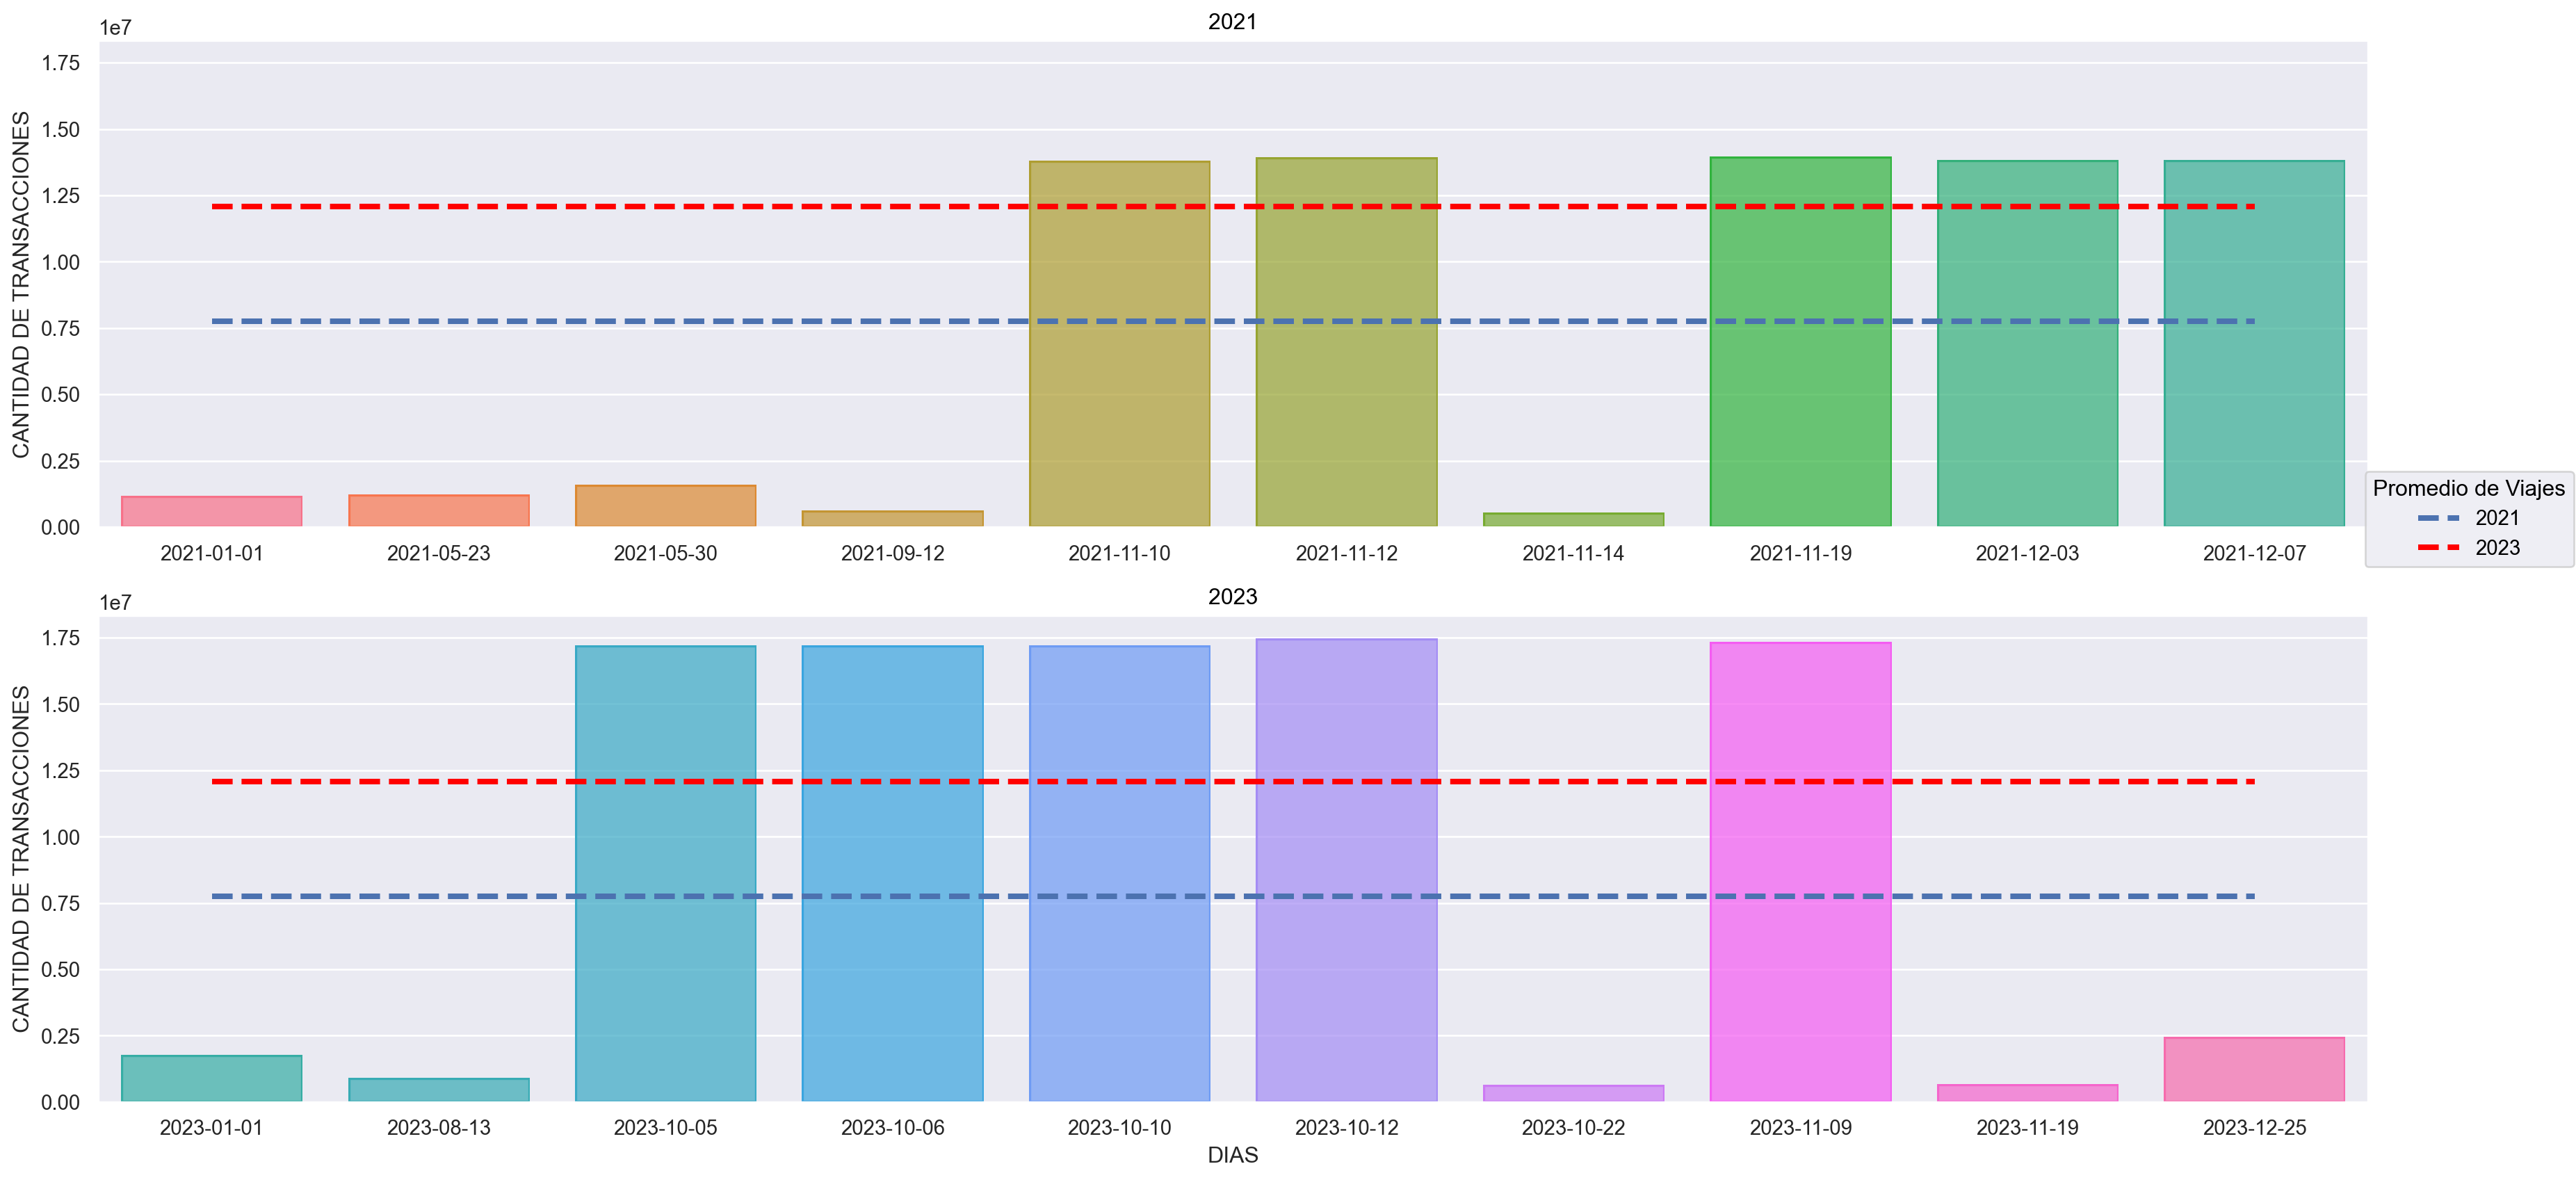

In [21]:
(
    so.Plot(
        data = extremos_ord,
        x = 'DIA_TRANSPORTE',
        y = 'CANTIDAD'
    )
    .facet('AÑO', wrap = 1).share(x = False)
    .add(so.Line(linewidth = 3, linestyle = '--'), y = cantidad_por_dia_2021['CANTIDAD'].mean(), x = 'DIA_TRANSPORTE', label = '2021')
    .add(so.Line(linewidth = 3, linestyle = '--', color = 'red'), y = cantidad_por_dia_2023['CANTIDAD'].mean(), x = 'DIA_TRANSPORTE', label = '2023')
    .add(so.Bar(),color = 'DIA_TRANSPORTE', legend= False)
    .layout(size = (18,9))
    .label(x = 'DIAS', y = 'CANTIDAD DE TRANSACCIONES', legend= 'Promedio de Viajes')
)

Al analizar el 2023, nos dimos cuenta que los días con menos viajes eran los días en los cuales se llevaron a cabo elecciones, por lo que decidimos compararlo con los datos del 2021 (último año electoral). Observamos que, al igual que en el 2023, los días con menos transacciones de SUBE también fueron los dias de elecciones. Esto se puede deber a muchos factores, uno de ellos es que en los días de elecciones el transporte público no tiene costo, por lo que los viajes no son registrados por la SUBE, entonces el número de viajes puede ser mayor pero no se tiene registro de estos. Otro factor puede ser que estos días son no laborales por lo que no hay mucho movimiento en las calles.

También, al contar con la información de que las elecciones suelen llevarse a cabo los domingos, nos pareció conveniente comparar los datos obtenidos de los días electorales del 2021 y del 2023 con el promedio de viajes de los domingos en ambos años, lo que derivó en el siguiente grafico:

#### Día de eleciones comparado con domingos normales

In [22]:
elecciones = extremos_ord.nsmallest(5, 'CANTIDAD')
elecciones

,DIA_TRANSPORTE,CANTIDAD,AÑO
15,2021-11-14,546394,2021
16,2021-09-12,615958,2021
5,2023-10-22,655564,2023
6,2023-11-19,684308,2023
7,2023-08-13,909517,2023


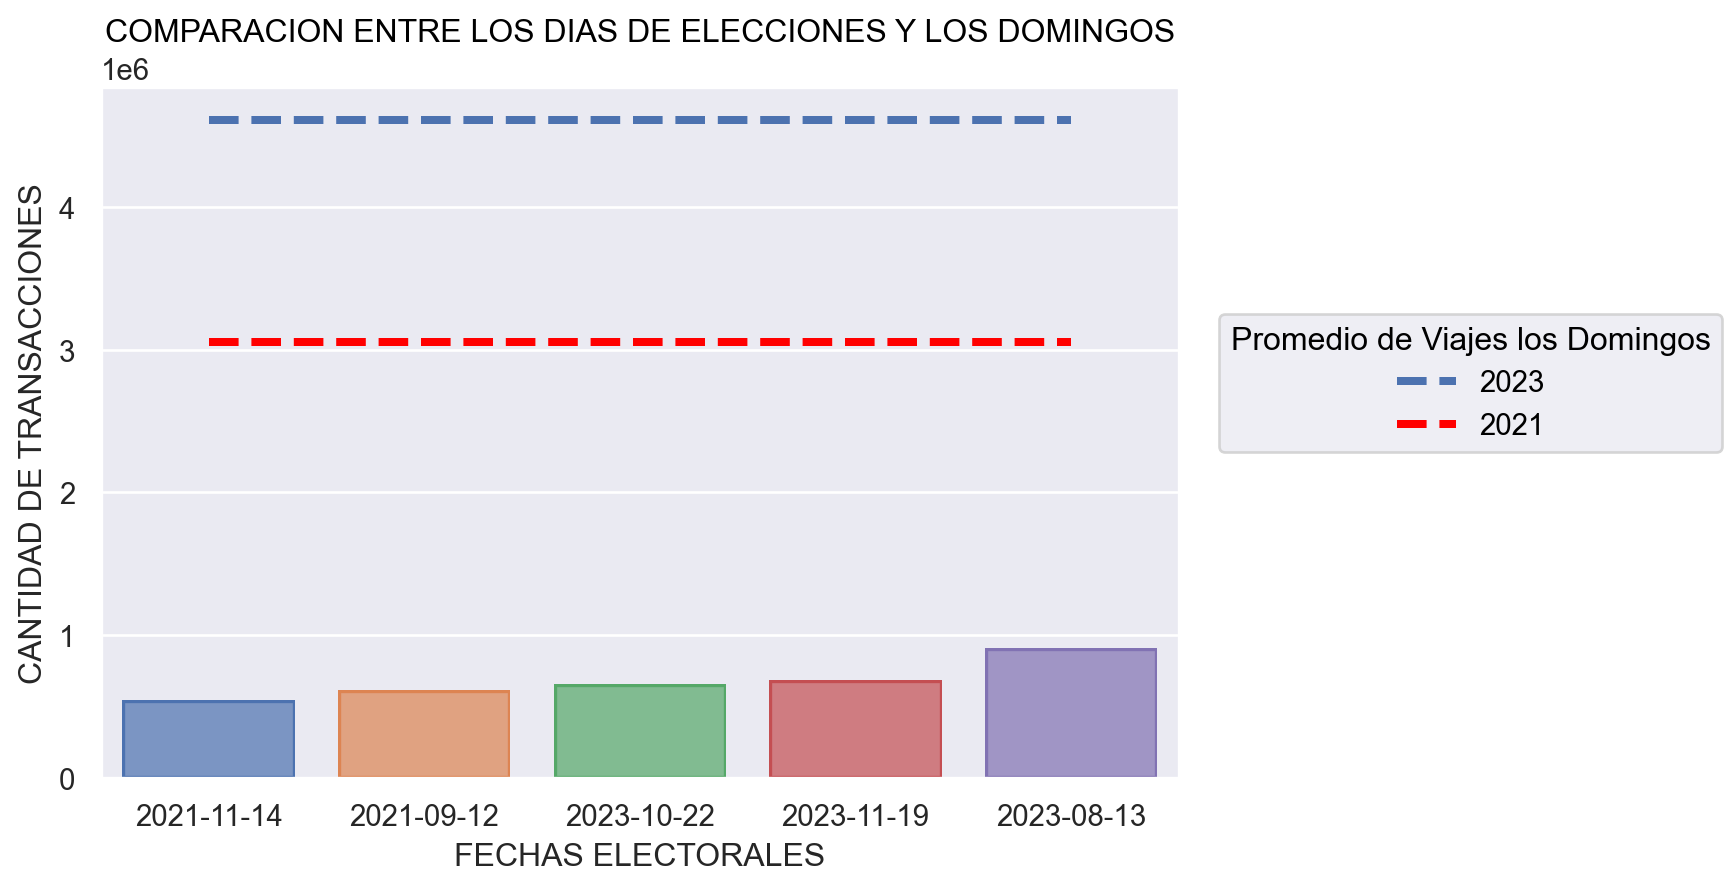

In [23]:
#Viajes registrados un domingo
domingos_2023 = datos_sube.loc[datos_sube['FECHA_DIA'] == 'Sun']
cant_domingo_2023 = domingos_2023.groupby('DIA_TRANSPORTE').CANTIDAD.sum()

sube_data_2021['DIA_TRANSPORTE'] = pd.to_datetime(sube_data_2021['DIA_TRANSPORTE'], format='%Y-%m-%d')

sube_data_2021['FECHA_DIA'] = sube_data_2021['DIA_TRANSPORTE'].dt.dayofweek
sube_data_2021 = sube_data_2021.replace({'FECHA_DIA': {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}})

domingos_2021 = sube_data_2021.loc[sube_data_2021['FECHA_DIA'] == 'Sun']
cant_domingo_2021 = domingos_2021.groupby('DIA_TRANSPORTE').CANTIDAD.sum()

elecciones = extremos_ord.nsmallest(5, 'CANTIDAD')

(
    so.Plot(
        data = elecciones,
        x = 'DIA_TRANSPORTE',
        y = 'CANTIDAD'
    )
    .add(so.Line(linewidth = 3, linestyle = '--'), y = cant_domingo_2023.mean(), x = 'DIA_TRANSPORTE', label = '2023')
    .add(so.Line(linewidth = 3, linestyle = '--', color = 'red'), y = cant_domingo_2021.mean(), x = 'DIA_TRANSPORTE', label = '2021')
    .add(so.Bar(), color = 'DIA_TRANSPORTE', legend= False)
    .label(title = 'COMPARACION ENTRE LOS DIAS DE ELECCIONES Y LOS DOMINGOS',x = 'FECHAS ELECTORALES', y = 'CANTIDAD DE TRANSACCIONES', legend= 'Promedio de Viajes los Domingos')
)

Esto nos muestra que el factor de que sean en domingo las elecciones no influye demasiado ya que los promedios de viajes de los domingos en 2021 y 2023 son ampliamente mayores a los datos registrados en los dias electorales.

# Modelado

## Ejercicio 5

### a)

In [24]:
sube_regresion = pd.read_csv('./data/sube-2023-regresion.csv')
sube_regresion.head()

,DIA_TRANSPORTE,NOMBRE_EMPRESA,LINEA,AMBA,TIPO_TRANSPORTE,JURISDICCION,PROVINCIA,MUNICIPIO,CANTIDAD,DATO_PRELIMINAR
0,2023-01-01,MUNICIPALIDAD DE MERCEDES PROVINCIA DE BUENOS ...,1,SI,COLECTIVO,MUNICIPAL,BUENOS AIRES,MERCEDES,61,NO
1,2023-01-01,MUNICIPALIDAD DE MERCEDES PROVINCIA DE BUENOS ...,2B,SI,COLECTIVO,MUNICIPAL,BUENOS AIRES,MERCEDES,11,NO
2,2023-01-01,EMPRESA BATAN S.A.,BS_AS_LINEA 715M,NO,COLECTIVO,MUNICIPAL,BUENOS AIRES,GENERAL PUEYRREDON,1707,NO
3,2023-01-01,COMPAÑIA DE TRANSPORTE VECINAL S.A.,BS_AS_LINEA_326,SI,COLECTIVO,PROVINCIAL,BUENOS AIRES,SN,438,NO
4,2023-01-01,EMPRESA DE TRANSPORTE PERALTA RAMOS SACI,BS_AS_LINEA_512,NO,COLECTIVO,MUNICIPAL,BUENOS AIRES,GENERAL PUEYRREDON,1189,NO


In [25]:
datos_ColectivoJN = sube_regresion[(sube_regresion['AMBA'] == 'SI') & (sube_regresion['TIPO_TRANSPORTE'] == 'COLECTIVO') & (sube_regresion['PROVINCIA'] == 'JN')]
cols = datos_ColectivoJN .LINEA.unique () # Los nombres de las lineas de colectivo

In [26]:
pasajeros_por_linea = pd.DataFrame()
for col in cols:
    datos_linea = datos_ColectivoJN[datos_ColectivoJN.LINEA == col][['DIA_TRANSPORTE', 'CANTIDAD']]
    datos_linea = datos_linea.set_index('DIA_TRANSPORTE').rename(columns ={'CANTIDAD' : col })
    pasajeros_por_linea = pd.concat([pasajeros_por_linea , datos_linea], axis = 1)

pasajeros_por_linea

,BS_ASLINEA_123,BSAS_LINEA_002,BSAS_LINEA_009,BSAS_LINEA_010,BSAS_LINEA_015,BSAS_LINEA_017,BSAS_LINEA_019,BSAS_LINEA_020,BSAS_LINEA_021,BSAS_LINEA_022,...,LINEA 5,LINEA 50,LINEA 6,LINEA 7,LINEA 76,LINEA 8,LINEA_099,LINEA_119_AMBA,LINEA_164_AMBA,LINEA 119
DIA_TRANSPORTE,,,,,,,,,,,,,,,,,,,,,
2023-01-01,1681,5670,5644,5177,9109,7013,1604,2617,11235,2202,...,4832.0,4839,2449,2184,3797,5317,1882,1573.0,3210,NaN
2023-01-02,9440,21759,23284,21176,45269,29962,13921,11934,55611,13823,...,20333.0,16221,10486,12774,17374,23250,10322,7345.0,19362,NaN
2023-01-04,10540,24755,25405,23806,52873,33659,16172,13366,61721,16206,...,23041.0,18448,12193,13949,19860,26294,11981,7925.0,21784,NaN
2023-01-05,10408,25772,26489,24688,53436,35182,16569,12929,62510,16863,...,23928.0,18481,12888,14668,21235,27216,11787,7597.0,22972,NaN
2023-01-06,10530,26021,26458,24167,53163,35212,16459,12955,63528,16846,...,24247.0,19300,12703,14199,23472,27073,11567,7811.0,23411,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,15957,35664,26684,31803,65544,47601,23197,16051,67748,24169,...,NaN,25838,16870,19426,28628,62260,15823,NaN,30177,13488.0
2023-12-23,8844,24236,19188,19964,43408,31986,12357,9859,50972,14347,...,NaN,13817,7896,9332,21468,43152,8991,NaN,16025,9699.0
2023-12-27,12721,29591,24693,29374,60347,41283,19417,14498,60169,22126,...,NaN,21545,13454,14923,25542,51921,11385,NaN,16931,13262.0


### b)

In [27]:
pasajeros_por_linea = pasajeros_por_linea.dropna(axis=1, how='any')
pasajeros_por_linea

,BS_ASLINEA_123,BSAS_LINEA_002,BSAS_LINEA_009,BSAS_LINEA_010,BSAS_LINEA_015,BSAS_LINEA_017,BSAS_LINEA_019,BSAS_LINEA_020,BSAS_LINEA_021,BSAS_LINEA_022,...,LINEA 4,LINEA 42,LINEA 44,LINEA 50,LINEA 6,LINEA 7,LINEA 76,LINEA 8,LINEA_099,LINEA_164_AMBA
DIA_TRANSPORTE,,,,,,,,,,,,,,,,,,,,,
2023-01-01,1681,5670,5644,5177,9109,7013,1604,2617,11235,2202,...,2942,4029,4649,4839,2449,2184,3797,5317,1882,3210
2023-01-02,9440,21759,23284,21176,45269,29962,13921,11934,55611,13823,...,15329,19072,20387,16221,10486,12774,17374,23250,10322,19362
2023-01-04,10540,24755,25405,23806,52873,33659,16172,13366,61721,16206,...,17836,21609,23595,18448,12193,13949,19860,26294,11981,21784
2023-01-05,10408,25772,26489,24688,53436,35182,16569,12929,62510,16863,...,18044,21993,23687,18481,12888,14668,21235,27216,11787,22972
2023-01-06,10530,26021,26458,24167,53163,35212,16459,12955,63528,16846,...,18122,22421,23731,19300,12703,14199,23472,27073,11567,23411
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,15957,35664,26684,31803,65544,47601,23197,16051,67748,24169,...,22421,30098,29079,25838,16870,19426,28628,62260,15823,30177
2023-12-23,8844,24236,19188,19964,43408,31986,12357,9859,50972,14347,...,14508,17630,19431,13817,7896,9332,21468,43152,8991,16025
2023-12-27,12721,29591,24693,29374,60347,41283,19417,14498,60169,22126,...,19319,25010,26433,21545,13454,14923,25542,51921,11385,16931


### c)

In [28]:
#Modificamos los nombres de las columnas para que sea más fácil operar
pasajeros_por_linea.columns = pasajeros_por_linea.columns.str.replace(' ', '_')

Para el primer modelo seleccionamos las lineas que más se parecían a la línea 009 (cantidad de pasajeros por día). Para eso utilizamos el siguiente código:

In [29]:
for i in range (len(pasajeros_por_linea.columns)):
    similitud = (pasajeros_por_linea['BSAS_LINEA_009'] - pasajeros_por_linea[pasajeros_por_linea.columns[i]]).mean()
    if (-1000 < similitud < 1000):
        print(pasajeros_por_linea.columns[i], similitud)

BSAS_LINEA_002 365.06
BSAS_LINEA_009 0.0
BSAS_LINEA_063 551.716
BSAS_LINEA_078 -920.952
BSAS_LINEA_091 237.032
BSAS_LINEA_146 147.02
BSAS_LINEA_169 183.884
LINEA_164_AMBA 596.728


Para el segundo modelo utilizamos librerias como SelectKBest y Random Forest para encontrar las líneas con mayor correlación a la línea 009:

In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression

X = pasajeros_por_linea.drop(columns=['BSAS_LINEA_009'])
y = pasajeros_por_linea['BSAS_LINEA_009']

#SelectKBest
selector = SelectKBest(score_func = f_regression, k = 5)
X_nuevo = selector.fit_transform(X, y)
top_select = X.columns[selector.get_support()]

#Random Forest
modelo = RandomForestRegressor()
modelo.fit(X, y)
indices_importantes = modelo.feature_importances_
indices = np.argsort(indices_importantes)[-5:]
top_rf = X.columns[indices]

print('SelectKBest: ', top_select)
print('Random Forest: ', top_rf)

SelectKBest:  Index(['BSAS_LINEA_024', 'BSAS_LINEA_146', 'LINEA_101', 'LINEA_107',
       'LINEA_7'],
      dtype='object')
Random Forest:  Index(['BSAS_LINEA_057', 'LINEA_28', 'BSAS_LINEA_168', 'BSAS_LINEA_056',
       'BSAS_LINEA_130'],
      dtype='object')


Para el tercer modelo utilizamos la libreria xgboost para encontrar las líneas con mayor correlación a la línea 009, también hicimos regresión Ridge:

In [42]:
import xgboost as xgb
top_features = 'asd'
X = pasajeros_por_linea.drop(columns=['BSAS_LINEA_009'])
y = pasajeros_por_linea['BSAS_LINEA_009']

xgb_model = xgb.XGBRegressor()
xgb_model.fit(X, y)

feature_importances = xgb_model.feature_importances_

#Pasamos el modelo a un dataframe
feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': feature_importances})

#Armamos la lista con el top características más importantes
top_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(5)['Feature'].tolist()

print(top_features)

['BSAS_LINEA_130', 'LINEA_101', 'LINEA_28', 'BSAS_LINEA_108', 'LINEA_23']


### d)

In [32]:
cv = KFold(n_splits=5, random_state=15, shuffle=True)

In [33]:
modelo1_formulaic = 'BSAS_LINEA_009 ~ BSAS_LINEA_002 + BSAS_LINEA_091 + BSAS_LINEA_146 + BSAS_LINEA_169 + BSAS_LINEA_063'
y1, X1 = (Formula(modelo1_formulaic)).get_model_matrix(pasajeros_por_linea)

In [34]:
modelo2_formulaic = 'BSAS_LINEA_009 ~ LINEA_101 + BSAS_LINEA_146 + LINEA_7 + BSAS_LINEA_024 + LINEA_107'
y2, X2 = (Formula(modelo2_formulaic)).get_model_matrix(pasajeros_por_linea)

In [35]:
modelo3_formulaic = 'BSAS_LINEA_009 ~ LINEA_28 + LINEA_101 + BSAS_LINEA_108 + LINEA_23 + BSAS_LINEA_130'
y3, X3 = (Formula(modelo3_formulaic)).get_model_matrix(pasajeros_por_linea)

In [36]:
alphas = np.array([0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000, 10000000, 100000000, 1000000000])

In [37]:
#Selección del mejor alpha para Ridge
for alpha in alphas:
    modelo3 = linear_model.Ridge(alpha = alpha, fit_intercept = False)    
    rmse3 = np.zeros(cv.get_n_splits())
    i = 0

    for train_index, val_index in cv.split(X3):
        X_train, X_val, y_train, y_val = X3.iloc[train_index], X3.iloc[val_index], y3.iloc[train_index], y3.iloc[val_index]
        modelo3.fit(X_train, y_train)

        y_pred = modelo3.predict(X_val)
        rmse3[i] = np.sqrt(mean_squared_error(y_val, y_pred))
        i += 1

    print(f'Para alpha = {alpha}, rmse: {rmse3.mean():.5f}')

Para alpha = 0.01, rmse: 1858.24426
Para alpha = 0.1, rmse: 1858.17975
Para alpha = 1.0, rmse: 1857.58148
Para alpha = 10.0, rmse: 1854.22198
Para alpha = 100.0, rmse: 1850.21607
Para alpha = 1000.0, rmse: 1849.33988
Para alpha = 10000.0, rmse: 1849.24161
Para alpha = 100000.0, rmse: 1849.22826
Para alpha = 1000000.0, rmse: 1849.19325
Para alpha = 10000000.0, rmse: 1848.89151
Para alpha = 100000000.0, rmse: 1848.57077
Para alpha = 1000000000.0, rmse: 1891.05552


### e)

Los tres modelos son de la misma forma, todos sumando las lineas deseadas en formulaic. Exceptuando por el tercer modelo que se utilizó regresión Ridge.

In [38]:
#Modelo 1
modelo1 = linear_model.LinearRegression(fit_intercept = False)
rmse1 = np.zeros(cv.get_n_splits())
i = 0

for train_index, val_index in cv.split(X1):
    X_train, X_val, y_train, y_val = X1.iloc[train_index], X1.iloc[val_index], y1.iloc[train_index], y1.iloc[val_index]
    modelo1.fit(X_train, y_train)
    
    y_pred = modelo1.predict(X_val)
    rmse1[i] = np.sqrt(mean_squared_error(y_val, y_pred))
    i += 1

#Modelo 2
modelo2 = linear_model.LinearRegression(fit_intercept = False)
rmse2 = np.zeros(cv.get_n_splits())
i = 0

for train_index, val_index in cv.split(X2):
    X_train, X_val, y_train, y_val = X2.iloc[train_index], X2.iloc[val_index], y2.iloc[train_index], y2.iloc[val_index]
    modelo2.fit(X_train, y_train)
    
    y_pred = modelo2.predict(X_val)
    rmse2[i] = np.sqrt(mean_squared_error(y_val, y_pred))
    i += 1

#Modelo 3
modelo3 = linear_model.Ridge(alpha = 100000000.0, fit_intercept = False)  
rmse3 = np.zeros(cv.get_n_splits())
i = 0

for train_index, val_index in cv.split(X3):
    X_train, X_val, y_train, y_val = X3.iloc[train_index], X3.iloc[val_index], y3.iloc[train_index], y3.iloc[val_index]
    modelo3.fit(X_train, y_train)
    
    y_pred = modelo3.predict(X_val)
    rmse3[i] = np.sqrt(mean_squared_error(y_val, y_pred))
    i += 1

In [39]:
print('Modelo 1:', rmse1.mean())
print('Modelo 2:', rmse2.mean())
print('Modelo 3 (Ridge):', rmse3.mean())

Modelo 1: 2134.5874771235985
Modelo 2: 1970.197098458293
Modelo 3 (Ridge): 1848.5707731783816


El modelo más efectivo fue el tercero, ya que siempre tiene el error cuadrático medio menor al alternar las validaciones.

### f)

Utilizaremos el modelo 3, con un alpha = 100000000

modelo3 = 'BSAS_LINEA_009 ~ LINEA_28 + LINEA_101 + BSAS_LINEA_108 + LINEA_23 + BSAS_LINEA_130'

alpha = 100000000